# Markovovy řetězce a lineární rovnice

*Nad rámec cvičení — oddíl 6.1 skripta.*

---

Soustava lineárních rovnic je úloha bez jediného náhodného prvku. Přesto se dá řešit náhodnou procházkou — a v jednom konkrétním případě je to i nejlepší, co se dá udělat.

Ten případ: **chcete jednu složku řešení obrovské soustavy.** Gaussova eliminace musí spočítat všechny, i kdyby vás zajímala jedna jediná. Náhodná procházka umí jít rovnou pro ni.

- **Neumannova řada** jako most mezi soustavou rovnic a sčítáním
- **von Neumannova–Ulamova procházka**: jedna cesta = jeden člen řady
- ověření, že to opravdu dává správné řešení
- kdy se to vyplatí a kdy je to nesmysl

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky

## 1. Od soustavy k řadě

Soustavu zapíšeme v iteračním tvaru

$$x = Ax + b$$

(z $Mx = c$ se tam dostaneme třeba rozkladem $M = I - A$). Dosazujeme-li opakovaně samo do sebe,

$$x = b + Ab + A^2b + A^3b + \dots = \sum_{k=0}^{\infty} A^k b .$$

To je **Neumannova řada** a konverguje, právě když spektrální poloměr $\rho(A) < 1$. Postačující a snadno ověřitelná podmínka je

$$\|A\|_\infty = \max_i \sum_j |a_{ij}| < 1 .$$

Rozepsáním $i$-té složky dostaneme obyčejný součet přes cesty:

$$x_i = \sum_{k=0}^{\infty}\ \sum_{j_1,\dots,j_k} a_{i j_1}a_{j_1 j_2}\cdots a_{j_{k-1} j_k}\, b_{j_k}.$$

Každý sčítanec odpovídá **cestě** $i \to j_1 \to j_2 \to \dots \to j_k$ po indexech. A sčítat přes cesty už umíme náhodně — je to součet řady metodou z `ch01_05_kdy_se_mc_vyplati`, jen ve více rozměrech.

## 2. Procházka po indexech

Postavíme náhodnou procházku, která cestu vylosuje. Ze stavu $s$ přejdeme do $t$ s pravděpodobností $p_{st}$, a se zbývající pravděpodobností

$$p_s^{\text{konec}} = 1 - \sum_t p_{st}$$

skončíme. Cestě přiřadíme **váhu**, která opraví rozdíl mezi tím, s jakou pravděpodobností jsme cestu vylosovali, a jakou má mít v součtu:

$$W_0 = 1, \qquad W_{k} = W_{k-1}\cdot\frac{a_{s_{k-1}s_k}}{p_{s_{k-1}s_k}} .$$

Odhadovač je součet příspěvků přes všechny navštívené stavy:

$$\xi = \sum_{k=0}^{T} W_k\, b_{s_k}, \qquad E\,\xi = x_i .$$

**Volba $p$ je volná a chytrá volba se vyplatí.** Když položíme

$$p_{st} = |a_{st}| \qquad\text{(možné právě díky } \|A\|_\infty < 1),$$

vyjde $W_k = \pm 1$ — váhy se vůbec nerozutečou, což je přesně to, co u vážení podle důležitosti (cvičení 7) chceme.

In [2]:
def nahodna_soustava(n, hustota=1.0, norma=0.7, seed=7):
    """Náhodná matice A s ||A||_∞ = norma a vektor b. Vrací A jako seznam řádků (j, a_ij)."""
    rnd = random.Random(seed)
    A = []
    for _ in range(n):
        sloupce = rnd.sample(range(n), min(n, max(1, int(round(n * hustota)))))
        hodnoty = [rnd.uniform(-1, 1) for _ in sloupce]
        s = sum(abs(v) for v in hodnoty)
        A.append([(j, v / s * norma) for j, v in zip(sloupce, hodnoty)])
    b = [rnd.uniform(0, 2) for _ in range(n)]
    return A, b


def neumann_iterace(A, b, kroku=200):
    """Referenční řešení: x <- A x + b (konverguje, protože ||A||_∞ < 1)."""
    n = len(b)
    x = b[:]
    for _ in range(kroku):
        novy = b[:]
        for i, radek in enumerate(A):
            novy[i] += sum(a * x[j] for j, a in radek)
        x = novy
    return x


def prochazka(A, b, i0):
    """Jedna realizace odhadovače x_{i0} (von Neumann–Ulam)."""
    s, W, acc = i0, 1.0, 0.0
    while True:
        acc += W * b[s]
        u = random.random()
        cum = 0.0
        dalsi = None
        for j, a in A[s]:
            cum += abs(a)
            if u < cum:
                dalsi = (j, a)
                break
        if dalsi is None:
            return acc                      # procházka skončila
        j, a = dalsi
        W *= a / abs(a)                     # = ±1, váhy se nerozutečou
        s = j


def odhad(A, b, i0, N):
    s = s2 = 0.0
    for _ in range(N):
        v = prochazka(A, b, i0)
        s += v
        s2 += v * v
    m = s / N
    return m, math.sqrt(max(s2 / N - m * m, 0.0) / N)


A, b = nahodna_soustava(6)
x = neumann_iterace(A, b)
print(f"{'složka':>8s} {'procházka':>22s} {'přesně':>10s} {'odchylka':>10s}")
for i in range(6):
    m, se = odhad(A, b, i, 100_000)
    print(f"x[{i}] {m:>14.5f} +- {se:<6.5f} {x[i]:>10.5f} {abs(m - x[i]) / se:>7.2f} se")
    assert abs(m - x[i]) < 5 * se

  složka              procházka     přesně   odchylka
x[0]        1.28474 +- 0.00554    1.27945    0.95 se
x[1]        0.85179 +- 0.00556    0.85510    0.60 se
x[2]        0.69349 +- 0.00519    0.69762    0.80 se
x[3]        1.63354 +- 0.00514    1.63960    1.18 se
x[4]        2.09692 +- 0.00569    2.10608    1.61 se
x[5]        0.60685 +- 0.00534    0.59767    1.72 se


Všech šest složek sedí. Procházka opravdu řeší soustavu rovnic.

Je dobré si uvědomit, **co se právě stalo**: algoritmus nikdy nesestavil matici, neprovedl eliminaci ani neinvertoval. Jen chodil náhodně po indexech a sčítal váhy.

## 3. Kdy se to vyplatí

Pro soustavu o šesti neznámých je to nesmysl — Gaussova eliminace ji vyřeší přesně a okamžitě. Zajímavé je něco jiného.

**Cena jedné procházky nezávisí na $n$.** Závisí jen na tom, jak dlouho procházka chodí, a to je dáno normou $\|A\|_\infty$ (očekávaná délka je $1/(1-\|A\|_\infty)$), ne velikostí soustavy. Přímé metody potřebují $O(n^3)$, respektive $O(n \cdot \text{nnz})$ u iteračních metod — a vždy spočítají **všechny** složky.

Takže: chcete-li jednu složku z milionové soustavy, procházka vyhraje. Vyzkoušíme na rostoucím $n$.

      n       procházka (1 složka)    iterace (všechny)  referenční x[3]
     50        1.00699 +- 0.00703   0.06 s          0.00 s          1.00082
    200        1.45502 +- 0.00763   0.06 s          0.01 s          1.47899
    800        0.16101 +- 0.00722   0.06 s          0.05 s          0.15657
   3200        0.59166 +- 0.00707   0.06 s          0.19 s          0.58618


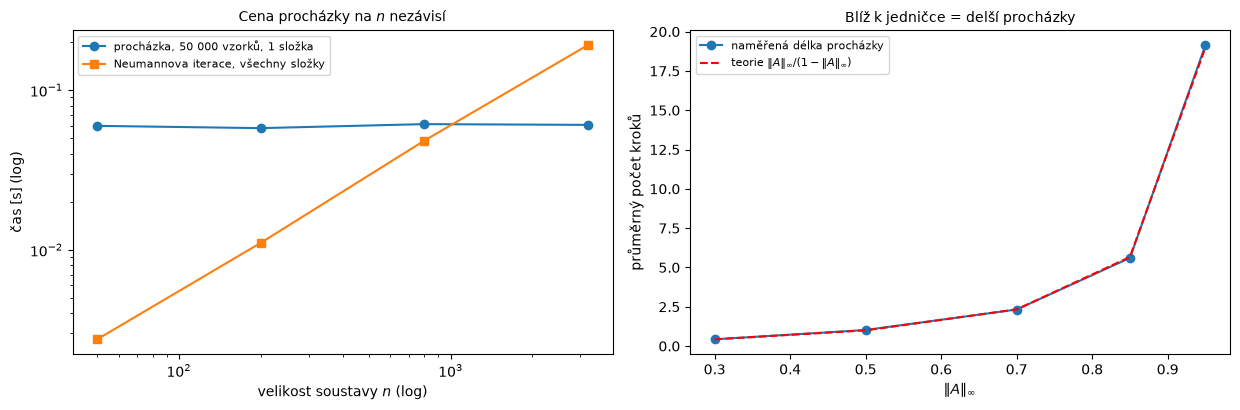

In [3]:
print(f"{'n':>7s} {'procházka (1 složka)':>26s} {'iterace (všechny)':>20s} {'referenční x[3]':>16s}")
ns, t_mc, t_it = [], [], []
for n in (50, 200, 800, 3200):
    A, b = nahodna_soustava(n, hustota=min(1.0, 8 / n), norma=0.7, seed=11)

    t0 = time.perf_counter()
    m, se = odhad(A, b, 3, 50_000)
    cas_mc = time.perf_counter() - t0

    t0 = time.perf_counter()
    x = neumann_iterace(A, b, kroku=120)
    cas_it = time.perf_counter() - t0

    ns.append(n); t_mc.append(cas_mc); t_it.append(cas_it)
    print(f"{n:>7d} {m:>14.5f} +- {se:<5.5f} {cas_mc:>6.2f} s {cas_it:>13.2f} s {x[3]:>16.5f}")
    assert abs(m - x[3]) < 5 * se

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
ax.loglog(ns, t_mc, "o-", label="procházka, 50 000 vzorků, 1 složka")
ax.loglog(ns, t_it, "s-", label="Neumannova iterace, všechny složky")
ax.set_xlabel("velikost soustavy $n$ (log)")
ax.set_ylabel("čas [s] (log)")
ax.set_title("Cena procházky na $n$ nezávisí", fontsize=10)
ax.legend(fontsize=8)

# jak délka procházky závisí na normě
ax = axes[1]
normy = (0.3, 0.5, 0.7, 0.85, 0.95)
delky, chyby = [], []
for norma in normy:
    A, b = nahodna_soustava(100, hustota=0.1, norma=norma, seed=5)
    celkem = 0
    for _ in range(20_000):
        s, kroku = 3, 0
        while True:
            u, cum, dalsi = random.random(), 0.0, None
            for j, a in A[s]:
                cum += abs(a)
                if u < cum:
                    dalsi = j
                    break
            if dalsi is None:
                break
            s = dalsi
            kroku += 1
        celkem += kroku
    delky.append(celkem / 20_000)
    chyby.append(odhad(A, b, 3, 20_000)[1])
ax.plot(normy, delky, "o-", label="naměřená délka procházky")
ax.plot(normy, [1 / (1 - x_) - 1 for x_ in normy], "r--", label=r"teorie $\|A\|_\infty/(1-\|A\|_\infty)$")
ax.set_xlabel(r"$\|A\|_\infty$")
ax.set_ylabel("průměrný počet kroků")
ax.set_title("Blíž k jedničce = delší procházky", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Levý graf ukazuje ten hlavní bod: čas procházky je **vodorovná čára** — soustava může růst libovolně, cena jedné složky se nemění. Iterace roste s velikostí soustavy.

Pravý graf ukazuje, kde je hranice použitelnosti. Délka procházky roste jako $1/(1-\|A\|_\infty)$, takže pro matici blízko hranice konvergence jsou procházky dlouhé a metoda se zadrhne. Je to stejná potíž, jakou mají iterační metody — jen se projeví jinak.

**Kdy tedy sáhnout po procházce:**

| | |
|---|---|
| ✓ | obrovská řídká soustava, zajímá vás pár složek |
| ✓ | matici nelze sestavit, ale umíte spočítat $a_{ij}$ na vyžádání |
| ✓ | stačí nízká přesnost (chyba klesá jako $1/\sqrt N$, na tři platné cifry potřebujete $\sim 10^6$ procházek) |
| ✗ | chcete celé řešení |
| ✗ | chcete vysokou přesnost |
| ✗ | $\rho(A)$ blízko 1 |

Historická poznámka: právě tahle úloha stála u zrodu metody. Von Neumann a Ulam ji navrhli v 40. letech v Los Alamos a jméno „Monte Carlo" je z téže doby a téhož místa.

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Iterační tvar | $x = Ax + b$, řešení $x = \sum_k A^k b$ (Neumannova řada) |
| Podmínka | $\rho(A) < 1$; stačí $\|A\|_\infty < 1$ |
| Cesta = člen řady | $i \to j_1 \to \dots \to j_k$ odpovídá $a_{ij_1}\cdots a_{j_{k-1}j_k}b_{j_k}$ |
| Odhadovač | $\xi = \sum_k W_k b_{s_k}$, $W_k = W_{k-1}a_{st}/p_{st}$ |
| Chytrá volba $p$ | $p_{st} = \lvert a_{st}\rvert \Rightarrow W = \pm 1$, váhy se nerozutečou |
| Délka procházky | v průměru $\|A\|_\infty/(1 - \|A\|_\infty)$ kroků |
| Hlavní výhoda | cena **nezávisí na $n$** a počítá se jen jedna složka |

### Zkuste si

1. Zkuste $p_{st}$ rovnoměrné místo $\lvert a_{st}\rvert$. Odhad zůstane nestranný — o kolik vzroste rozptyl?
2. Odhadněte funkcionál $(h, x) = \sum_i h_i x_i$ místo jedné složky: stačí začínat procházku v náhodném $i$ s pravděpodobností úměrnou $h_i$.
3. Sestrojte matici s $\|A\|_\infty = 1.05$ a ukažte, že procházky nekončí a odhad diverguje.
4. Pro $\|A\|_\infty = 0.9$ změřte, kolik procházek je potřeba na tři platné cifry. Porovnejte s cenou Neumannovy iterace.
5. Spočítejte $A^{-1}_{ij}$ (jeden prvek inverze) tím, že za $b$ dosadíte $j$-tý jednotkový vektor.